# Exploratory Data Analysis (EDA)
**DTSC 2302 Group 21:** Ryan Williams, Eshan Khandekar, Will Arboscello

Before modeling, we look at the data: what it contains, and whether payroll and metro GDP per capita
relate to winning. **Figures 1 and 2 are the exploratory figures on our poster.**

**Run `mlb_models.ipynb` first.** It creates `data/team_seasons.csv` (432 team-seasons, 2002–2016),
which this notebook reads. Charts are saved to `figures/` at 300 dpi for printing.

In [1]:
# Setup: libraries, chart style, and the merged dataset
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Path("figures").mkdir(exist_ok=True)
BLUE = "#2a78d6"
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
                     "grid.linewidth": 0.6, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.axisbelow": True})
pd.options.display.float_format = "{:,.3f}".format

data = pd.read_csv("data/team_seasons.csv")
print(f"{len(data)} team-seasons | {data['yearID'].min()}-{data['yearID'].max()} | "
      f"{data['franchID'].nunique()} franchises | {data['metro'].nunique()} metro areas")

432 team-seasons | 2002-2016 | 29 franchises | 25 metro areas


## 1. Summary statistics
Win % centers on .500 (as it must, since every win is someone else's loss). Relative payroll of 1.0 = league average.

In [2]:
cols = {"win_pct": "Win %", "prev_win_pct": "Last season's win %", "rel_payroll": "Relative payroll",
        "population": "Metro population", "gdp_per_capita": "Metro GDP per capita ($)"}
summary = data[list(cols)].describe().T[["mean", "std", "min", "50%", "max"]].rename(index=cols, columns={"50%": "median"})
summary

,mean,std,min,median,max
Win %,0.500,0.071,0.265,0.500,0.648
Last season's win %,0.500,0.072,0.265,0.505,0.716
Relative payroll,1.006,0.412,0.177,0.933,2.855
Metro population,"6,463,664.312","5,316,080.728","1,621,310.639","4,785,756.096","23,527,544.001"
Metro GDP per capita ($),"57,860.208","9,447.880","38,326.000","57,254.000","83,556.000"


## 2. How do the variables relate to win %?
Correlation (r) runs from −1 to 1; 0 means no straight-line relationship.

In [3]:
corr = data[["win_pct", "prev_win_pct", "rel_payroll", "population", "gdp_per_capita"]].corr().round(2)
corr = corr.rename(index=cols, columns=cols)
print(f"Payroll vs. win %:            r = {data['rel_payroll'].corr(data['win_pct']):.2f}")
print(f"GDP per capita vs. win %:     r = {data['gdp_per_capita'].corr(data['win_pct']):.2f}")
print(f"GDP per capita vs. payroll:   r = {data['gdp_per_capita'].corr(data['rel_payroll']):.2f}")
corr

Payroll vs. win %:            r = 0.41
GDP per capita vs. win %:     r = 0.14
GDP per capita vs. payroll:   r = 0.32


,Win %,Last season's win %,Relative payroll,Metro population,Metro GDP per capita ($)
Win %,1.000,0.540,0.410,0.230,0.140
Last season's win %,0.540,1.000,0.500,0.230,0.150
Relative payroll,0.410,0.500,1.000,0.580,0.320
Metro population,0.230,0.230,0.580,1.000,0.280
Metro GDP per capita ($),0.140,0.150,0.320,0.280,1.000


## Figure 1: Relative payroll vs. win %
Payroll is the strongest money-related predictor in past research (Scully, 1974; Hall et al., 2002).

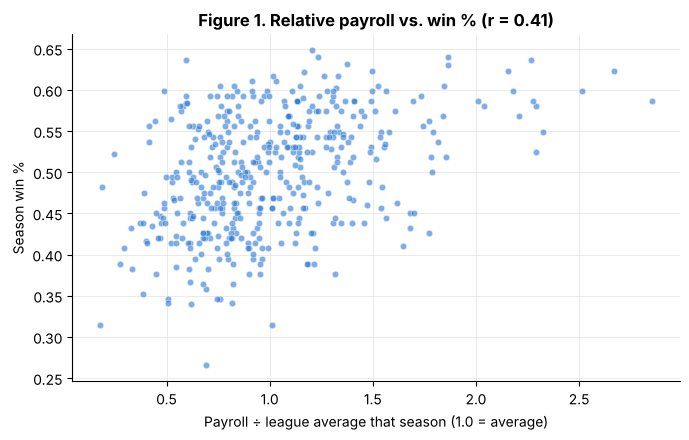

In [4]:
r = data["rel_payroll"].corr(data["win_pct"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(data["rel_payroll"], data["win_pct"], s=22, alpha=0.6, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set(title=f"Figure 1. Relative payroll vs. win % (r = {r:.2f})",
       xlabel="Payroll ÷ league average that season (1.0 = average)", ylabel="Season win %")
fig.tight_layout(); fig.savefig("figures/fig1_payroll_vs_win_pct.png"); plt.show()

## Figure 2: Metro GDP per capita vs. win %
Our key new variable. GDP per capita is from the **previous year**, matching what the models use.

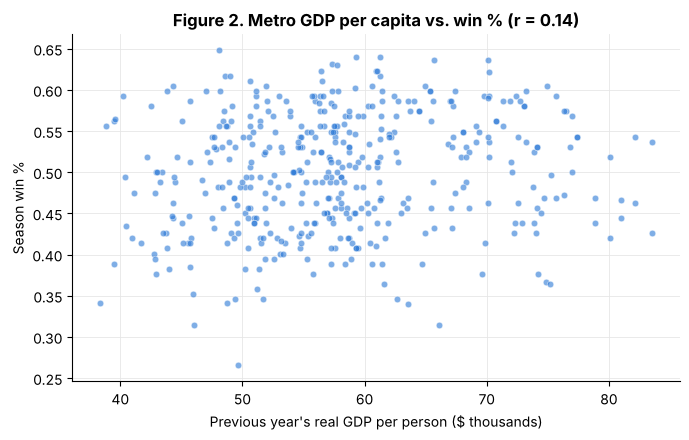

In [5]:
r = data["gdp_per_capita"].corr(data["win_pct"])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(data["gdp_per_capita"] / 1000, data["win_pct"], s=22, alpha=0.6, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set(title=f"Figure 2. Metro GDP per capita vs. win % (r = {r:.2f})",
       xlabel="Previous year's real GDP per person ($ thousands)", ylabel="Season win %")
fig.tight_layout(); fig.savefig("figures/fig2_gdp_per_capita_vs_win_pct.png"); plt.show()

## 3. Outliers worth mentioning
The biggest spenders relative to the league (the 2005 Yankees spent 2.9× the average), and the best and worst records.

In [6]:
show = ["yearID", "name", "rel_payroll", "win_pct"]
print("Highest relative payrolls:")
print(data.nlargest(5, "rel_payroll")[show].to_string(index=False))
print("\nBest and worst records:")
print(pd.concat([data.nlargest(3, "win_pct"), data.nsmallest(3, "win_pct")])[show].to_string(index=False))

Highest relative payrolls:
 yearID             name  rel_payroll  win_pct
   2005 New York Yankees        2.855    0.586
   2004 New York Yankees        2.669    0.623
   2006 New York Yankees        2.516    0.599
   2008 New York Yankees        2.323    0.549
   2013 New York Yankees        2.293    0.525

Best and worst records:
 yearID                 name  rel_payroll  win_pct
   2004  St. Louis Cardinals        1.206    0.648
   2016         Chicago Cubs        1.232    0.640
   2002     New York Yankees        1.866    0.640
   2003       Detroit Tigers        0.693    0.265
   2004 Arizona Diamondbacks        1.011    0.315
   2013       Houston Astros        0.177    0.315


## What the EDA tells us
- **Payroll** has a clear positive link to winning (r = 0.41).
- **GDP per capita** has only a weak link to winning (r = 0.14), but a stronger one to payroll (r = 0.32).
  This hints that a city's wealth may matter mainly *through* payroll, which the models then test.
- These are correlations, not causes.